# Intro

In [65]:
import numpy as np 
import pandas as pd
import yfinance as yf 
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import root_mean_squared_error

In [66]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device

device(type='cpu')

In [67]:
ticker = "AAPL"
df = yf.download(ticker, "2022-01-01")

df

[*********************100%***********************]  1 of 1 completed


Price,Close,High,Low,Open,Volume
Ticker,AAPL,AAPL,AAPL,AAPL,AAPL
Date,,,,,
2022-01-03,177.786362,178.636183,173.586157,173.703368,104487900
2022-01-04,175.529968,178.694788,174.963426,178.391984,99310400
2022-01-05,170.860931,175.989104,170.587430,175.442101,94537600
2022-01-06,168.008713,171.232139,167.657066,168.692466,96904000
2022-01-07,168.174759,170.099046,167.061213,168.878052,86709100
...,...,...,...,...,...
2026-09-28,338.399994,342.989990,338.040009,340.369995,32820800
2026-09-29,329.399994,337.089996,328.700012,336.970001,38478000


<Axes: xlabel='Date'>

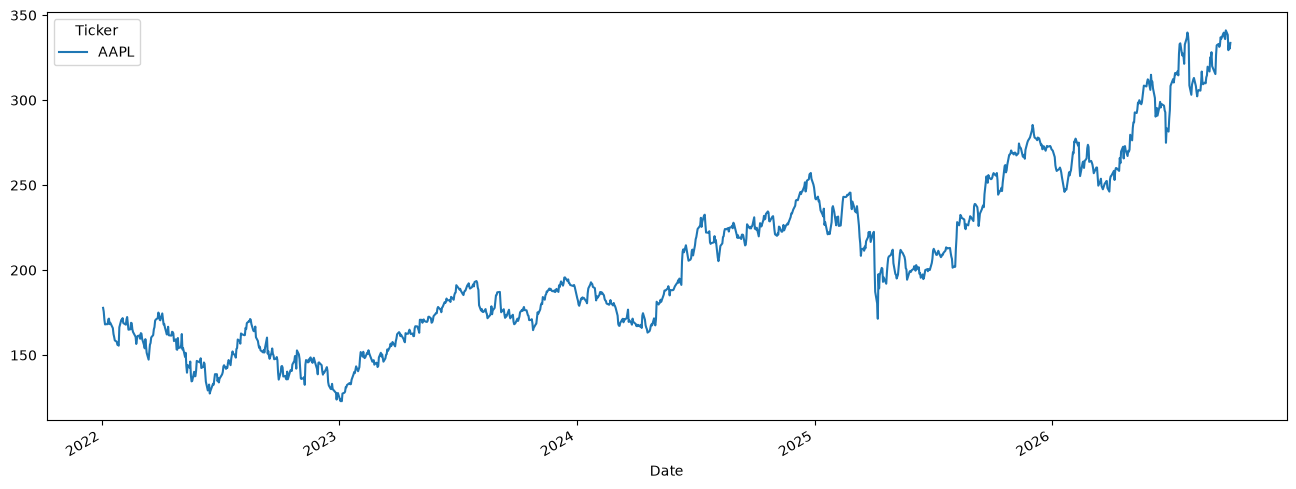

In [68]:
df.Close.plot(figsize=(16, 6))

### PreProcessing

In [69]:
#Scale all of the data

In [70]:
scaler = StandardScaler()

df["Close"] = scaler.fit_transform(df["Close"])

In [71]:
df["Close"]

Ticker,AAPL
Date,
2022-01-03,-0.537045
2022-01-04,-0.580888
2022-01-05,-0.671611
2022-01-06,-0.727031
2022-01-07,-0.723805
...,...
2026-09-28,2.583792
2026-09-29,2.408915
2026-09-30,2.479254


In [72]:
seq_length = 30
data = []

for i in range(len(df) - seq_length):
    data.append(df.Close[i:i+seq_length])

data = np.array(data)

data

array([[[-0.53704476],
        [-0.58088808],
        [-0.67161077],
        ...,
        [-0.72059254],
        [-0.7867262 ],
        [-0.78216502]],

       [[-0.58088808],
        [-0.67161077],
        [-0.72703139],
        ...,
        [-0.7867262 ],
        [-0.78216502],
        [-0.70786011]],

       [[-0.67161077],
        [-0.72703139],
        [-0.723805  ],
        ...,
        [-0.78216502],
        [-0.70786011],
        [-0.71242041]],

       ...,

       [[ 2.03254263],
        [ 2.1646712 ],
        [ 2.05721941],
        ...,
        [ 2.63567194],
        [ 2.58379169],
        [ 2.40891533]],

       [[ 2.1646712 ],
        [ 2.05721941],
        [ 2.01932989],
        ...,
        [ 2.58379169],
        [ 2.40891533],
        [ 2.47925439]],

       [[ 2.05721941],
        [ 2.01932989],
        [ 2.0385661 ],
        ...,
        [ 2.40891533],
        [ 2.47925439],
        [ 2.42679184]]], shape=(1162, 30, 1))

In [73]:
# Train/Test split 
train_size = int(0.8 * len(data))

X_train = torch.from_numpy(data[:train_size, :-1, :]).type(torch.Tensor).to(device)
Y_train = torch.from_numpy(data[:train_size, -1, :]).type(torch.Tensor).to(device)
X_test = torch.from_numpy(data[train_size:, :-1, :]).type(torch.Tensor).to(device)
Y_test = torch.from_numpy(data[train_size:, -1, :]).type(torch.Tensor).to(device)

In [74]:
class PredictionModel(nn.Module): 

    def __init__(self, input_dim, hidden_dim, num_layers, output_dim): 
        super(PredictionModel, self).__init__()

        self.num_layers = num_layers
        self.hidden_dim = hidden_dim

        self.lstm = nn.LSTM(input_dim, hidden_dim, num_layers, batch_first=True)
        self.fc = nn.Linear(hidden_dim, output_dim)

    def forward(self, x):
        h0 = torch.zeros(self.num_layers, x.size(0), self.hidden_dim, device=device)
        c0 = torch.zeros(self.num_layers, x.size(0), self.hidden_dim, device=device)

        out, (hn, cn) = self.lstm(x, (h0.detach(), c0.detach()))
        out = self.fc(out[:, -1, :])

        return out

In [75]:
model = PredictionModel(input_dim=1, hidden_dim=32, num_layers=2, output_dim=1).to(device)

In [76]:
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=0.01)

In [77]:
num_epochs = 200

for i in range(num_epochs):
    y_train_pred = model(X_train)

    loss = criterion(y_train_pred, Y_train)

    if i % 25 == 0:
        print(i, loss)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

0 tensor(0.5214, grad_fn=<MseLossBackward0>)
25 tensor(0.0116, grad_fn=<MseLossBackward0>)
50 tensor(0.0077, grad_fn=<MseLossBackward0>)
75 tensor(0.0062, grad_fn=<MseLossBackward0>)
100 tensor(0.0053, grad_fn=<MseLossBackward0>)
125 tensor(0.0047, grad_fn=<MseLossBackward0>)
150 tensor(0.0042, grad_fn=<MseLossBackward0>)
175 tensor(0.0040, grad_fn=<MseLossBackward0>)


#Predictions

In [78]:
model.eval()

y_test_pred = model(X_test)

y_train_pred = scaler.inverse_transform(y_train_pred.detach().cpu().numpy())
y_train = scaler.inverse_transform(Y_train.detach().cpu().numpy())
y_test_pred = scaler.inverse_transform(y_test_pred.detach().cpu().numpy())
y_test = scaler.inverse_transform(Y_test.detach().cpu().numpy())

In [79]:
train_rmse = root_mean_squared_error(y_train[:, 0], y_train_pred[:, 0])
test_rmse = root_mean_squared_error(y_test[:, 0], y_test_pred[:, 0])

print(f"Train RMSE = {train_rmse}, Test RMSE = {test_rmse}")

Train RMSE = 3.25270676612854, Test RMSE = 6.184954643249512


## Plot Predictions and Root Mean Squared Error 

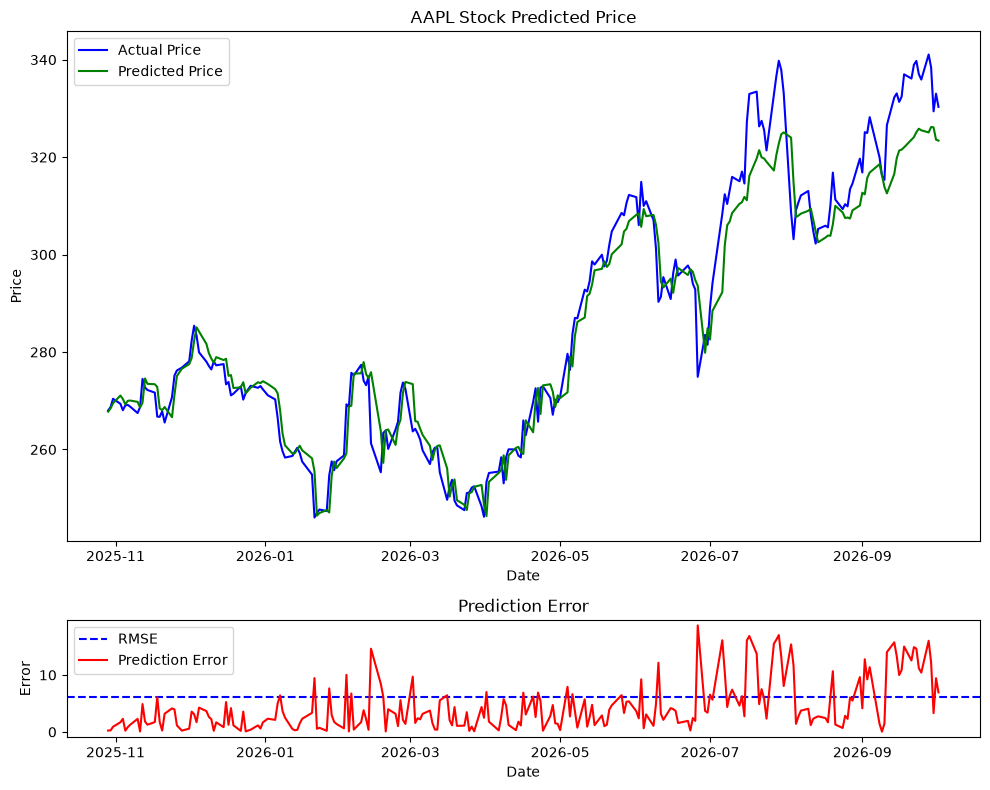

In [81]:
fig = plt.figure(figsize=(10, 8))

gs = fig.add_gridspec(4, 1)

ax1 = fig.add_subplot(gs[:3, 0])
ax1.plot(df.iloc[-len(y_test):].index, y_test, color = "blue", label = "Actual Price")
ax1.plot(df.iloc[-len(y_test):].index, y_test_pred, color = "green", label = "Predicted Price")
ax1.legend()
plt.title(f"{ticker} Stock Predicted Price")
plt.xlabel("Date")
plt.ylabel("Price")

ax2 = fig.add_subplot(gs[3, 0])
ax2.axhline(test_rmse, color = "blue", linestyle = "--", label = "RMSE")
ax2.plot(df[-len(y_test):].index, abs(y_test - y_test_pred), color = "red", label = "Prediction Error")
ax2.legend()
plt.title("Prediction Error")
plt.xlabel("Date")
plt.ylabel("Error")
plt.tight_layout()

plt.show()